In [13]:
import requests
from bs4 import BeautifulSoup


In [14]:
import requests
from bs4 import BeautifulSoup

url = "https://www.keralauniversity.ac.in/affiliated-colleges"

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"
}

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("HTML length:", len(response.text))

response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Page title:", soup.title.get_text(strip=True))

Status code: 200
Final URL: https://www.keralauniversity.ac.in/affiliated-colleges
HTML length: 601488
Page title: University of Kerala


In [15]:
# Find headings that may contain college names
headings = soup.find_all(["h2", "h3", "h4", "h5"])

print("Number of headings:", len(headings))

for heading in headings:
    print(
        "Heading:", heading.get_text(" ", strip=True),
        "| HTML tag:", heading.name
    )

Number of headings: 207
Heading: University of Kerala | HTML tag: h4
Heading: Affiliated Colleges | HTML tag: h4
Heading: List of Affiliated Colleges in Alphabetic Order | HTML tag: h2
Heading: A. J. College of Science and Technology, Thonnakkal | HTML tag: h4
Heading: All Saints' College, Thiruvananthapuram | HTML tag: h4
Heading: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram | HTML tag: h4
Heading: Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram | HTML tag: h4
Heading: B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram | HTML tag: h4
Heading: Baby John Memorial Govt. College, Chavara | HTML tag: h4
Heading: Badhiriya B.Ed. Training College, Velichikkala, Kollam | HTML tag: h4
Heading: Baselios Marthoma Mathews II Training College, Kottarakara | HTML tag: h4
Heading: Bishop Jerome School of Architecture, Fathima College Road, Kollam | HTML tag: h4
Heading: Bishop Jesudasan CSI Arts & Science College, 

In [16]:
links = soup.find_all("a", href=True)

print("Total links:", len(links))

for link in links[:20]:
    print(
        "Text:", link.get_text(" ", strip=True),
        "| URL:", link["href"]
    )

Total links: 574
Text: University of Kerala | URL: index.php
Text: Home | URL: index.php
Text: About ▾ ▾ | URL: #
Text: General ▾ ▾ | URL: #
Text: Grievance Redressal | URL: grievance-redressal
Text: A-Z index | URL: a-z-index
Text: Instrumentation Facility (CLIF) | URL: http://kusicc.ac.in
Text: Site map | URL: site-map
Text: Overview | URL: our-history
Text: University Act and Statutes | URL: acts-statutes
Text: Institutional Development Plan | URL: /downloads/IDP_UOK_final_version.pdf
Text: Recognition / Approval | URL: recognition-approval
Text: Annual Reports | URL: annual-reports
Text: NAAC | URL: /NAAC
Text: Institutional Data (NIRF) | URL: nirf
Text: QS Rankings | URL: QS-ranking
Text: ARIIA Report | URL: ARIIA-Report
Text: Annual Accounts | URL: annual-accounts
Text: Budget Estimate | URL: budget-estimate
Text: Vision & Mission | URL: vision-mission


In [17]:
html_lower = response.text.lower()

print("Contains mailto links:", "mailto:" in html_lower)
print("Contains tel links:", "tel:" in html_lower)
print("Contains email text:", "email" in html_lower)
print("Contains phone text:", "phone" in html_lower)
print("Contains pagination text:", "pagination" in html_lower)

Contains mailto links: False
Contains tel links: False
Contains email text: False
Contains phone text: False
Contains pagination text: False


In [18]:
email_links = soup.select('a[href^="mailto:"]')

print("Email links found:", len(email_links))

for link in email_links[:10]:
    print(link.get("href"))

Email links found: 0


In [19]:
phone_links = soup.select('a[href^="tel:"]')

print("Telephone links found:", len(phone_links))

for link in phone_links[:10]:
    print(link.get("href"))

Telephone links found: 0


In [20]:
# Find all h4 headings
all_h4 = soup.find_all("h4")

# Extract and clean the text from each heading
college_names = [
    heading.get_text(" ", strip=True)
    for heading in all_h4
]

# Print the number of headings
print("Total h4 headings:", len(college_names))

# Display the first 10 entries
for i, name in enumerate(college_names[:10], start=1):
    print(i, name)

Total h4 headings: 206
1 University of Kerala
2 Affiliated Colleges
3 A. J. College of Science and Technology, Thonnakkal
4 All Saints' College, Thiruvananthapuram
5 Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram
6 Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram
7 B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram
8 Baby John Memorial Govt. College, Chavara
9 Badhiriya B.Ed. Training College, Velichikkala, Kollam
10 Baselios Marthoma Mathews II Training College, Kottarakara


In [21]:
# Find the first college heading
first_college = soup.find(
    "h4",
    string=lambda text: text and
    "A. J. College of Science and Technology" in text
)

if first_college:
    print(first_college.parent.parent.prettify()[:5000])
else:
    print("College heading not found.")

<div class="col-sm-12 col-md-12 col-lg-12" style="border-bottom:1px solid #999; padding-bottom:15px; padding-top:15px;">
 <div class="school-list-item">
  <h4 style="text-align:left">
   <a href="http://www.ajcollege.in" style="color:#FFF; text-decoration:none" target="_blank">
    A. J. College of Science and Technology, Thonnakkal
   </a>
  </h4>
  <p style="font-weight:bold;">
   Thiruvananthapuram
   <font color="orange">
    |
   </font>
   Estd. 
            	    							1995
   <font color="orange">
    |
   </font>
   Self Financing
  </p>
  <p style="font-size:85%; padding-right:19px;">
   A. J. College of Science and Technology was established in 1995 on the side of national high way near Kumaran Asan Memorial. It was the fulfillment of a long cherished desire of the management to start an institution of higher education offering degree and post graduate cour...
  </p>
  <div class="col-sm-12 col-md-12 col-lg-12" style="padding-left:0px; margin-top:10px;">
   <div class="col-m

In [22]:
# Find all college heading elements
all_h4 = soup.find_all("h4")

college_records = []

for heading in all_h4:
    # Find the college name
    name = heading.get_text(" ", strip=True)

    # Find the form inside the surrounding college listing
    container = heading.find_parent(
        "div",
        class_="school-list-item"
    )

    if container:
        form = container.find(
            "form",
            attrs={"name": "CollegeDetailsForm"}
        )

        if form:
            college_id = form.find(
                "input",
                attrs={"name": "collegeCol"}
            )

            if college_id:
                college_records.append({
                    "College Name": name,
                    "College ID": college_id.get("value")
                })

print("College records found:", len(college_records))

for record in college_records[:10]:
    print(record)

College records found: 204
{'College Name': 'A. J. College of Science and Technology, Thonnakkal', 'College ID': '5'}
{'College Name': "All Saints' College, Thiruvananthapuram", 'College ID': '4'}
{'College Name': 'Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram', 'College ID': '59'}
{'College Name': 'Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram', 'College ID': '231'}
{'College Name': 'B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram', 'College ID': '170'}
{'College Name': 'Baby John Memorial Govt. College, Chavara', 'College ID': '229'}
{'College Name': 'Badhiriya B.Ed. Training College, Velichikkala, Kollam', 'College ID': '87'}
{'College Name': 'Baselios Marthoma Mathews II Training College, Kottarakara', 'College ID': '130'}
{'College Name': 'Bishop Jerome School of Architecture, Fathima College Road, Kollam', 'College ID': '271'}
{'College Name': 'Bishop Jesudasan CSI Arts & Science College, Mu

In [23]:
college_records[0]

{'College Name': 'A. J. College of Science and Technology, Thonnakkal',
 'College ID': '5'}

In [24]:
details_url = "https://www.keralauniversity.ac.in/affiliated-college-details"

# Create a session to maintain cookies between requests
session = requests.Session()

session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"
})

# Select the first extracted college
first_record = college_records[0]

payload = {
    "collegeCol": first_record["College ID"]
}

response_details = session.post(
    details_url,
    data=payload,
    timeout=30
)

print("Status code:", response_details.status_code)
print("Final URL:", response_details.url)
print("Response length:", len(response_details.text))

response_details.raise_for_status()

details_soup = BeautifulSoup(
    response_details.text,
    "html.parser"
)

print("Page title:",
      details_soup.title.get_text(strip=True)
      if details_soup.title else "No title found")

Status code: 200
Final URL: https://www.keralauniversity.ac.in/affiliated-college-details
Response length: 97149
Page title: University of Kerala


In [25]:
page_text = details_soup.get_text(" ", strip=True)

for keyword in [
    "Contact Address",
    "Contact No",
    "Email",
    "Web URL"
]:
    print(
        keyword,
        "found:", keyword.lower() in page_text.lower()
    )

Contact Address found: True
Contact No found: True
Email found: True
Web URL found: True


In [26]:
for element in details_soup.find_all(
    string=lambda text: text and any(
        keyword.lower() in text.lower()
        for keyword in [
            "Contact Address",
            "Contact No",
            "Email",
            "Web URL"
        ]
    )
):
    print(element.parent.parent.get_text(" ", strip=True))

Contact Address : The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317 Contact No : 0471 2618644 | 0471 2618106 Email : ajcollegeprincipal@gmail.com Web URL : www.ajcollege.in Courses Offered : B.A. Journalism, Mass Communication & Video Production (30), English and Communicative English (24) BSc Computer Science (30), Botany & Biotechnology (30), Biochemistry & Industrial Microbiology (30) BMS Hotel Management and Catering Science (30) BBA (30) B.Com [Elective - Computer Application] (40), BCom [Elective - Finance] (40)
Bcom Tax Procedure and Practice(40) MA Mass Communication and Journalism (12) M.A English Language and Literature (15) MSc Microbiology (10), Biotechnology (10), Computer Science (10), Biochemistry (10), M.Com Finance(12) Details of all courses under University of Kerala: Click Here
Contact Address : The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317 Contact No : 047

In [27]:
# Find the element containing "Contact Address"
address_label = details_soup.find(
    string=lambda text: text and "Contact Address" in text
)

if address_label:
    print(address_label.parent.parent.prettify()[:3000])
else:
    print("Contact Address label not found")

<span style=" ;font-size: 90%; line-height:25px;">
 <br>
  Contact Address :
  <b>
   The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
  </b>
  <br/>
  Contact No :
  <b>
   0471 2618644
  </b>
  <b>
   | 0471 2618106
  </b>
  <br/>
  Email :
  <b>
   ajcollegeprincipal@gmail.com
  </b>
  <br/>
  Web URL :
  <a href="http://www.ajcollege.in" target="_blank">
   <b>
    www.ajcollege.in
   </b>
  </a>
  <br/>
  <b>
   Courses Offered :
  </b>
  <br/>
  B.A. Journalism, Mass Communication &amp; Video Production (30), English and Communicative English (24)
  <br/>
  BSc Computer Science (30), Botany &amp; Biotechnology (30), Biochemistry &amp; Industrial Microbiology (30)
  <br/>
  BMS Hotel Management and Catering Science (30)
  <br/>
  BBA (30)
  <br>
   B.Com [Elective - Computer Application] (40), BCom [Elective - Finance] (40)
Bcom Tax Procedure and Practice(40)
   <br/>
   MA Mass Communication and Journalism (12)
   <br/>
   M.

In [30]:
# Find the span containing the contact information
contact_span = details_soup.find(
    "span",
    string=lambda text: text and "Contact Address" in text
)

print(contact_span)

None


In [31]:
contact_span = next(
    (
        span for span in details_soup.find_all("span")
        if "Contact Address" in span.get_text(" ", strip=True)
        and "Contact No" in span.get_text(" ", strip=True)
    ),
    None
)

if contact_span:
    print(contact_span.get_text(" ", strip=True))
else:
    print("Contact details container not found.")

Contact Address : The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317 Contact No : 0471 2618644 | 0471 2618106 Email : ajcollegeprincipal@gmail.com Web URL : www.ajcollege.in Courses Offered : B.A. Journalism, Mass Communication & Video Production (30), English and Communicative English (24) BSc Computer Science (30), Botany & Biotechnology (30), Biochemistry & Industrial Microbiology (30) BMS Hotel Management and Catering Science (30) BBA (30) B.Com [Elective - Computer Application] (40), BCom [Elective - Finance] (40)
Bcom Tax Procedure and Practice(40) MA Mass Communication and Journalism (12) M.A English Language and Literature (15) MSc Microbiology (10), Biotechnology (10), Computer Science (10), Biochemistry (10), M.Com Finance(12) Details of all courses under University of Kerala: Click Here


In [32]:
if contact_span:
    bold_elements = contact_span.find_all("b")

    print("Bold elements found:", len(bold_elements))

    for element in bold_elements[:6]:
        print(element.get_text(" ", strip=True))

Bold elements found: 7
The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
0471 2618644
| 0471 2618106
ajcollegeprincipal@gmail.com
www.ajcollege.in
Courses Offered :


In [33]:
if contact_span:
    # Find the email address
    email_link = contact_span.select_one('a[href^="mailto:"]')

    email = (
        email_link["href"].replace("mailto:", "").strip()
        if email_link else None
    )

    # Find the college website
    website_link = contact_span.find(
        "a",
        href=lambda href: href and
        not href.startswith("mailto:")
    )

    website = website_link.get("href") if website_link else None

    print("Email:", email)
    print("Website:", website)

Email: None
Website: http://www.ajcollege.in


In [34]:
if contact_span:
    for link in contact_span.find_all("a", href=True):
        print(
            "Link text:", link.get_text(" ", strip=True),
            "| href:", link["href"]
        )

Link text: www.ajcollege.in | href: http://www.ajcollege.in
Link text: Click Here | href: https://exams.keralauniversity.ac.in/Login/check4


In [35]:
email = None

if contact_span:
    for link in contact_span.find_all("a", href=True):
        href = link["href"].strip()

        if href.lower().startswith("mailto:"):
            email = href.split(":", 1)[1].strip()
            break

print("Email:", email)

Email: None


In [36]:
address = None
phone_numbers = []

if contact_span:
    bold_elements = contact_span.find_all("b")

    if len(bold_elements) >= 2:
        address = bold_elements[0].get_text(" ", strip=True)

        phone_text = bold_elements[1].get_text(" ", strip=True)

        # Split the two numbers using the vertical bar
        phone_numbers = [
            number.strip()
            for number in phone_text.split("|")
            if number.strip()
        ]

print("Address:", address)
print("Phone numbers:", phone_numbers)

Address: The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
Phone numbers: ['0471 2618644']


In [37]:
phone_numbers = []

if contact_span:
    bold_elements = contact_span.find_all("b")

    # The first bold element is the address.
    # The next bold elements contain phone numbers.
    for element in bold_elements[1:]:
        text = element.get_text(" ", strip=True)

        if any(char.isdigit() for char in text):
            if "|" in text:
                phone_numbers.extend(
                    number.strip()
                    for number in text.split("|")
                    if number.strip()
                )
            else:
                phone_numbers.append(text)

print("Phone numbers:", phone_numbers)

Phone numbers: ['0471 2618644', '0471 2618106']


In [38]:
if contact_span:
    print(
        "Email text present:",
        "ajcollegeprincipal@gmail.com" in
        contact_span.get_text(" ", strip=True)
    )

    print(
        "Email in HTML:",
        "ajcollegeprincipal@gmail.com" in str(contact_span)
    )

Email text present: True
Email in HTML: True


In [39]:
import re

email = None

if contact_span:
    text = contact_span.get_text(" ", strip=True)

    match = re.search(
        r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
        text
    )

    if match:
        email = match.group(0)

print("Email:", email)

Email: ajcollegeprincipal@gmail.com


In [41]:
import re
import time
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

details_url = (
    "https://www.keralauniversity.ac.in/"
    "affiliated-college-details"
)

def extract_college_details(session, record):
    college_name = record["College Name"]
    college_id = record["College ID"]

    result = {
        "College Name": college_name,
        "College ID": college_id,
        "Address": None,
        "Contact Number": None,
        "Email Address": None,
        "Website URL": None,
        "Status": "Not processed"
    }

    try:
        response = session.post(
            details_url,
            data={"collegeCol": college_id},
            timeout=30
        )
        response.raise_for_status()

        page = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # Find the section containing contact details
        contact_span = next(
                 span for span in page.find_all("span")
                if "Contact Address" in span.get_text()
                and "Contact No" in span.get_text()
            (
           ),
            None
        )

        if not contact_span:
            result["Status"] = "Contact section not found"
            return result

        text = contact_span.get_text(" ", strip=True)

        # Extract address
        address_match = re.search(
            r"Contact Address\s*:\s*(.*?)\s*Contact No\s*:",
            text,
            re.IGNORECASE
        )

        if address_match:
            result["Address"] = address_match.group(1).strip()

        # Extract phone numbers
        phone_match = re.search(
            r"Contact No\s*:\s*(.*?)\s*Email\s*:",
            text,
            re.IGNORECASE
        )

        if phone_match:
            numbers = re.findall(
                r"\+?\d[\d\s()-]{5,}\d",
                phone_match.group(1)
            )

            result["Contact Number"] = " | ".join(
                " ".join(number.split())
                for number in numbers
            ) or None

        # Extract email from visible text
        email_match = re.search(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            text
        )

        if email_match:
            result["Email Address"] = email_match.group(0)

        # Extract the college website from the Web URL section
        website_match = re.search(
            r"Web URL\s*:\s*(.*?)\s*Courses Offered\s*:",
            text,
            re.IGNORECASE
        )

        if website_match:
            website_text = website_match.group(1).strip()

            # Prefer the actual href when available
            website_link = contact_span.find(
                "a",
                href=lambda href: (
                    href
                    and not href.lower().startswith("mailto:")
                    and "keralauniversity.ac.in" not in href.lower()
                    and "exams.keralauniversity.ac.in" not in href.lower()
                )
            )

            if website_link:
                result["Website URL"] = urljoin(
                    details_url,
                    website_link["href"].strip()
                )
            else:
                result["Website URL"] = website_text or None

        result["Status"] = "Success"

    except requests.RequestException as error:
        result["Status"] = f"Request error: {error}"

    return result

In [58]:
test_result = extract_college_details(
    session,
    college_records[0]
)

for key, value in test_result.items():
    print(f"{key}: {value}")

College Name: A. J. College of Science and Technology, Thonnakkal
College ID: 5
Address: The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
Contact Number: 0471 2618644 | 0471 2618106
Email Address: ajcollegeprincipal@gmail.com
Website URL: http://www.ajcollege.in
Status: Success


In [59]:
all_results = []

for index, record in enumerate(college_records, start=1):
    result = extract_college_details(session, record)
    all_results.append(result)

    print(
        f"{index}/{len(college_records)} - "
        f"{record['College Name']}: {result['Status']}"
    )

    # Be polite to the university server
    time.sleep(1)

1/204 - A. J. College of Science and Technology, Thonnakkal: Success
2/204 - All Saints' College, Thiruvananthapuram: Success
3/204 - Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram: Success
4/204 - Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram: Success
5/204 - B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram: Success
6/204 - Baby John Memorial Govt. College, Chavara: Success
7/204 - Badhiriya B.Ed. Training College, Velichikkala, Kollam: Success
8/204 - Baselios Marthoma Mathews II Training College, Kottarakara: Success
9/204 - Bishop Jerome School of Architecture, Fathima College Road, Kollam: Success
10/204 - Bishop Jesudasan CSI Arts & Science College, Mulayara, Thiruvananthapuram: Success
11/204 - Bishop Moore College for the Hearing Impaired, Manakala, Adoor: Success
12/204 - Bishop Moore College, Mavelikkara, Alappuzha: Success
13/204 - Buddha College of Teacher Education, Cheppad, Muthukulam 

KeyboardInterrupt: 

In [44]:
import pandas as pd

df = pd.DataFrame(all_results)

print("Total records:", len(df))
print("\nProcessing status:")
print(df["Status"].value_counts(dropna=False))

df.to_csv(
    "kerala_university_colleges.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCSV file saved.")

Total records: 204

Processing status:
Status
Success                      191
Contact section not found     13
Name: count, dtype: int64

CSV file saved.


In [45]:
from google.colab import files

files.download("kerala_university_colleges.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
df = pd.read_csv("/content/kerala_university_colleges.csv")
df.head()

,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status
0,"A. J. College of Science and Technology, Thonn...",5,"The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in,Success
1,"All Saints' College, Thiruvananthapuram",4,NaN,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success
2,"Allama Iqbal Institute of Management, Peringam...",59,"The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com,Success
3,"Ayyankali Memorial Arts and Science College, K...",231,"The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com,Success
4,"B.N.V. College of Teacher Education, Thiruvall...",170,NaN,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   College Name    204 non-null    object
 1   College ID      204 non-null    int64 
 2   Address         125 non-null    object
 3   Contact Number  176 non-null    object
 4   Email Address   176 non-null    object
 5   Website URL     166 non-null    object
 6   Status          204 non-null    object
dtypes: int64(1), object(6)
memory usage: 11.3+ KB


In [49]:
df.isnull().sum()

,0
College Name,0
College ID,0
Address,79
Contact Number,28
Email Address,28
Website URL,38
Status,0


In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
# Display records with missing contact information
missing_contact = df[
    df[["Address", "Contact Number",
        "Email Address", "Website URL"]]
    .isna()
    .any(axis=1)
]

print("Records needing review:", len(missing_contact))

display(missing_contact[
    ["College Name", "College ID", "Address",
     "Contact Number", "Email Address", "Website URL", "Status"]
].head(20))

Records needing review: 110


,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status
1,"All Saints' College, Thiruvananthapuram",4,NaN,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success
4,"B.N.V. College of Teacher Education, Thiruvall...",170,NaN,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success
6,"Badhiriya B.Ed. Training College, Velichikkala...",87,NaN,0474 2026500 | 0474 2022828,principal@badhiriya.org,http://www.badhiriya.org,Success
8,"Bishop Jerome School of Architecture, Fathima ...",271,NaN,NaN,NaN,NaN,Contact section not found
10,"Bishop Moore College for the Hearing Impaired,...",243,"Bishop Moore College for the Hearing Impaired,...",04734-230661 | 9447309278,bmchimanakala@gmail.com,NaN,Success
11,"Bishop Moore College, Mavelikkara, Alappuzha",141,NaN,0479 2303260 | 0479 2303230 | 0479 2303230,bpmoorecollege@gmail.com,http://www.bishopmoorecollege.in,Success
12,"Buddha College of Teacher Education, Cheppad, ...",82,NaN,0479 2475576 | 0479 2475576,buddhacollege76@gmail.com,http://bcte.in,Success
14,"Carmel College, Muhamma, Alappuzha",245,NaN,0478 2868730 | +91 9446177578,carmelcollegemuhamma@gmail.com,http://www.carmelcollegemuhamma.org,Success
15,"Christ College, Vizhinjam, Thiruvananthapuram",246,NaN,0471 2480347 | 9447369933,christcollegevzm@hotmail.com,http://www.christcollegevizhinjam.com,Success
17,"Christ Nagar College of Education, Thiruvallam...",177,NaN,0471 2380216 | 0471 2380413 | 0471 2383733,christnagarcollegeofeducation@hotmail.com,http://www.christnagarcollege.org,Success


In [53]:
failed = df[df["Status"] != "Success"]

if not failed.empty:
    print("College:", failed.iloc[0]["College Name"])
    print("ID:", failed.iloc[0]["College ID"])

College: Bishop Jerome School of Architecture, Fathima College Road, Kollam
ID: 271


In [54]:
record = next(
    r for r in college_records
    if r["College ID"] == "271"
)

response_271 = session.post(
    details_url,
    data={"collegeCol": "271"},
    timeout=30
)

response_271.raise_for_status()

soup_271 = BeautifulSoup(
    response_271.text,
    "html.parser"
)

print("College:", record["College Name"])
print("Response length:", len(response_271.text))

print(
    soup_271.get_text(" ", strip=True)[:3000]
)

College: Bishop Jerome School of Architecture, Fathima College Road, Kollam
Response length: 94429
University of Kerala University of Kerala Home About ▾ ▾ General ▾ ▾ Grievance Redressal A-Z index Instrumentation Facility (CLIF) Site map Overview University Act and Statutes Institutional Development Plan Recognition / Approval Annual Reports NAAC Institutional Data (NIRF) QS Rankings ARIIA Report Annual Accounts Budget Estimate Vision & Mission Founder Why KU? Facts and Figures Administration ▾ ▾ Organogram Chart Chancellor Pro-Chancellor Vice Chancellor Registrar Finance Officer Controller of Examinations Ombudsperson Succession List ▾ ▾ Chancellors Pro-Chancellors Vice Chancellors Pro-Vice Chancellors Executive Bodies ▾ ▾ Senate Syndicate Statutory Officers Academic Council Boards of Studies Finance Committee Administrative Staff ▾ ▾ Directors Other Officers Personal Staff Joint Registrars Deputy Registrars Assistant Registrars Librarians Academic Leadership ▾ ▾ Deans of Faculties F

In [56]:
for span in soup_271.find_all("span"):
    text = span.get_text(" ", strip=True)

    if "Contact Address" in text or "Contact No" in text:
        print(text[:2000])

Contact Address : Bishop Jerome School of Architecture, Fathima College Road, Kollam Courses Offered : B.Arch Details of all courses under University of Kerala: Click Here


In [57]:
import re
import time
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

# URL of the University of Kerala college details page
details_url = (
    "https://www.keralauniversity.ac.in/"
    "affiliated-college-details"
)


def extract_college_details(session, record):

    # Get the college name and ID
    college_name = record["College Name"]
    college_id = record["College ID"]

    # Create a dictionary to store the extracted information
    result = {
        "College Name": college_name,
        "College ID": college_id,
        "Address": None,
        "Contact Number": None,
        "Email Address": None,
        "Website URL": None,
        "Status": "Not processed"
    }

    try:
        # Send a POST request for this college's details
        response = session.post(
            details_url,
            data={"collegeCol": college_id},
            timeout=30
        )

        # Raise an error if the request fails
        response.raise_for_status()

        # Parse the returned HTML
        page = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # Find the section containing the contact address.
        # Do not require Contact No because some colleges
        # may not display a phone number.
        contact_span = next(
            (
                span
                for span in page.find_all("span")
                if "Contact Address" in span.get_text(
                    " ", strip=True
                )
            ),
            None
        )

        # Stop if the contact section cannot be found
        if not contact_span:
            result["Status"] = "Contact section not found"
            return result

        # Convert the section into readable text
        text = contact_span.get_text(" ", strip=True)

        # --------------------------------------------------
        # 1. Extract the address
        # --------------------------------------------------
        address_match = re.search(
            r"Contact Address\s*:\s*(.*?)"
            r"(?=\s*Contact No\s*:|\s*Email\s*:|"
            r"\s*Web URL\s*:|\s*Courses Offered\s*:|$)",
            text,
            re.IGNORECASE
        )

        if address_match:
            address = address_match.group(1).strip()
            result["Address"] = address or None

        # --------------------------------------------------
        # 2. Extract phone number(s)
        # --------------------------------------------------
        phone_match = re.search(
            r"Contact No\s*:\s*(.*?)"
            r"(?=\s*Email\s*:|\s*Web URL\s*:|"
            r"\s*Courses Offered\s*:|$)",
            text,
            re.IGNORECASE
        )

        if phone_match:
            phone_text = phone_match.group(1)

            # Find phone-number-like sequences
            numbers = re.findall(
                r"\+?\d[\d\s()-]{4,}\d",
                phone_text
            )

            # Remove extra spaces and join multiple numbers
            cleaned_numbers = [
                " ".join(number.split())
                for number in numbers
            ]

            result["Contact Number"] = (
                " | ".join(cleaned_numbers)
                if cleaned_numbers
                else None
            )

        # --------------------------------------------------
        # 3. Extract email address
        # --------------------------------------------------
        email_match = re.search(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            text
        )

        if email_match:
            result["Email Address"] = email_match.group(0)

        # --------------------------------------------------
        # 4. Extract the college website
        # --------------------------------------------------
        website_match = re.search(
            r"Web URL\s*:\s*(.*?)"
            r"(?=\s*Courses Offered\s*:|$)",
            text,
            re.IGNORECASE
        )

        if website_match:
            website_text = website_match.group(1).strip()

            # Prefer the actual website link from the HTML
            website_link = contact_span.find(
                "a",
                href=lambda href: (
                    href
                    and not href.lower().startswith(
                        ("mailto:", "tel:", "javascript:")
                    )
                    and "keralauniversity.ac.in" not in href.lower()
                    and "exams.keralauniversity.ac.in" not in href.lower()
                )
            )

            if website_link:
                result["Website URL"] = urljoin(
                    details_url,
                    website_link["href"].strip()
                )
            elif website_text:
                # Use the displayed website text if no suitable
                # external link is available
                result["Website URL"] = website_text

        # Mark the record as processed
        result["Status"] = "Success"

    except requests.RequestException as error:
        # Store request errors without stopping the entire scraper
        result["Status"] = f"Request error: {error}"

    return result

In [60]:
# Create a session for sending requests
session = requests.Session()

session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"
})

# Test the first college
test_record = college_records[0]

test_result = extract_college_details(
    session,
    test_record
)

# Display the extracted information
for key, value in test_result.items():
    print(f"{key}: {value}")

College Name: A. J. College of Science and Technology, Thonnakkal
College ID: 5
Address: The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
Contact Number: 0471 2618644 | 0471 2618106
Email Address: ajcollegeprincipal@gmail.com
Website URL: http://www.ajcollege.in
Status: Success


In [62]:
import pandas as pd
import time

all_college_details = []

for i, record in enumerate(college_records, start=1):
    details = extract_college_details(session, record)
    all_college_details.append(details)

    print(
        f"Processed {i}/{len(college_records)}: "
        f"{record['College Name']} - {details['Status']}"
    )

    # Pause briefly between requests
    time.sleep(0.5)

# Convert results into a DataFrame
df = pd.DataFrame(all_college_details)

# Display the first five records
display(df.head())

# Show the dataset size
print("Total records:", len(df))

Processed 1/204: A. J. College of Science and Technology, Thonnakkal - Success
Processed 2/204: All Saints' College, Thiruvananthapuram - Success
Processed 3/204: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram - Success
Processed 4/204: Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram - Success
Processed 5/204: B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram - Success
Processed 6/204: Baby John Memorial Govt. College, Chavara - Success
Processed 7/204: Badhiriya B.Ed. Training College, Velichikkala, Kollam - Success
Processed 8/204: Baselios Marthoma Mathews II Training College, Kottarakara - Success
Processed 9/204: Bishop Jerome School of Architecture, Fathima College Road, Kollam - Success
Processed 10/204: Bishop Jesudasan CSI Arts & Science College, Mulayara, Thiruvananthapuram - Success
Processed 11/204: Bishop Moore College for the Hearing Impaired, Manakala, Adoor - Success
Processed 12/204: B

,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status
0,"A. J. College of Science and Technology, Thonn...",5,"The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in,Success
1,"All Saints' College, Thiruvananthapuram",4,None,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success
2,"Allama Iqbal Institute of Management, Peringam...",59,"The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com,Success
3,"Ayyankali Memorial Arts and Science College, K...",231,"The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com,Success
4,"B.N.V. College of Teacher Education, Thiruvall...",170,None,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success


Total records: 204


In [63]:
df.to_csv(
    "kerala_university_colleges.csv",
    index=False,
    encoding="utf-8-sig"
)

df.to_excel(
    "kerala_university_colleges.xlsx",
    index=False
)

print("CSV and Excel files saved successfully!")

CSV and Excel files saved successfully!


In [66]:
from google.colab import files

files.download("kerala_university_colleges.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
df = pd.read_csv("/content/kerala_university_colleges (1).csv")
df.head()

,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status
0,"A. J. College of Science and Technology, Thonn...",5,"The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in,Success
1,"All Saints' College, Thiruvananthapuram",4,NaN,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success
2,"Allama Iqbal Institute of Management, Peringam...",59,"The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com,Success
3,"Ayyankali Memorial Arts and Science College, K...",231,"The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com,Success
4,"B.N.V. College of Teacher Education, Thiruvall...",170,NaN,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success


In [68]:
df.isnull().sum()

,0
College Name,0
College ID,0
Address,67
Contact Number,13
Email Address,26
Website URL,31
Status,0


In [69]:
df.duplicated().sum()

np.int64(0)

In [73]:
df[df['Address'].isna()]

,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status
1,"All Saints' College, Thiruvananthapuram",4,NaN,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success
4,"B.N.V. College of Teacher Education, Thiruvall...",170,NaN,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success
6,"Badhiriya B.Ed. Training College, Velichikkala...",87,NaN,0474 2026500 | 0474 2022828,principal@badhiriya.org,http://www.badhiriya.org,Success
11,"Bishop Moore College, Mavelikkara, Alappuzha",141,NaN,0479 2303260 | 0479 2303230 | 0479 2303230,bpmoorecollege@gmail.com,http://www.bishopmoorecollege.in,Success
12,"Buddha College of Teacher Education, Cheppad, ...",82,NaN,0479 2475576 | 0479 2475576,buddhacollege76@gmail.com,http://bcte.in,Success
...,...,...,...,...,...,...,...
192,"T. K. Madhava Memorial College, Nangiarkulangara",149,NaN,0479 2412659 | 0479 2412659,tkmmcollege.principal2021@gmail.com,http://www.tkmmc.ac.in,Success
196,Travancore Arts And Science College,288,NaN,94472 24365,NaN,http://travancoreartsandsciencecollege.busines...,Success
197,University College Of Engineering,75,NaN,91-471-2417574,uceprincipal@yahoo.com,http://ucek.in,Success
199,"Valiyam Memorial College of Teacher Education,...",89,NaN,0476 2672115 | 0476 2672115,info@vmcollege.com,http://www.valiyambedcollege.com,Success


In [77]:

import requests
import pandas as pd
import re
from bs4 import BeautifulSoup

# 1. Website URL and request headers
directory_url = "https://www.keralauniversity.ac.in/affiliated-colleges"

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"
}

# 2. Request the webpage
response = requests.get(
    directory_url,
    headers=headers,
    timeout=30
)
response.raise_for_status()

# 3. Parse the HTML
soup = BeautifulSoup(response.text, "html.parser")

# 4. Find college entries
college_items = soup.select("div.school-list-item")

print("College entries found:", len(college_items))

extra_records = []

# 5. Extract district, establishment year and college type
for item in college_items:

    heading = item.find("h4")
    form = item.find("form", {"name": "CollegeDetailsForm"})

    if heading is None or form is None:
        continue

    id_input = form.find("input", {"name": "collegeCol"})

    if id_input is None:
        continue

    college_name = heading.get_text(" ", strip=True)
    college_id = str(id_input.get("value", "")).strip()

    # Get the visible text from the college entry
    text = item.get_text(" ", strip=True)

    district = None
    establishment_year = None
    college_type = None

    # Find the establishment year and college type
    match = re.search(
        r"Estd\.\s*(\d{4})\s*\|\s*"
        r"(Government\s+Self Financing|"
        r"Self Financing|Government|Aided|Autonomous)\b",
        text,
        re.IGNORECASE
    )

    if match:

        establishment_year = match.group(1)
        college_type = match.group(2).strip()

        # Extract the text before "Estd."
        prefix = text[:match.start()]

        # Remove the college name from the beginning
        if prefix.startswith(college_name):
            district_text = prefix[len(college_name):]
        else:
            district_text = prefix

        # Clean separators and extra whitespace
        district_text = district_text.strip(" |,-")

        district = district_text if district_text else None

    extra_records.append({
        "College ID": college_id,
        "Directory College Name": college_name,
        "District": district,
        "Establishment Year": establishment_year,
        "College Type": college_type
    })

# 6. Create a DataFrame
directory_df = pd.DataFrame(extra_records)

# 7. Display the results
display(directory_df.head(10))

print("\nExtra records collected:", len(directory_df))

print("\nMissing values in the extracted fields:")
print(
    directory_df[
        ["District", "Establishment Year", "College Type"]
    ].isna().sum()
)

# 8. Check for duplicate college IDs
print(
    "\nDuplicate college IDs:",
    directory_df["College ID"].duplicated().sum()
)


College entries found: 204


,College ID,Directory College Name,District,Establishment Year,College Type
0,5,"A. J. College of Science and Technology, Thonn...",Thiruvananthapuram,1995,Self Financing
1,4,"All Saints' College, Thiruvananthapuram",Thiruvananthapuram,1964,Aided
2,59,"Allama Iqbal Institute of Management, Peringam...",Thiruvananthapuram,2003,Self Financing
3,231,"Ayyankali Memorial Arts and Science College, K...",Kollam,2015,Aided
4,170,"B.N.V. College of Teacher Education, Thiruvall...",Thiruvananthapuram,2005,Self Financing
5,229,"Baby John Memorial Govt. College, Chavara",Kollam,1981,Government
6,87,"Badhiriya B.Ed. Training College, Velichikkala...",Kollam,2007,Self Financing
7,130,"Baselios Marthoma Mathews II Training College,...",Kollam,1995,Self Financing
8,271,"Bishop Jerome School of Architecture, Fathima ...",Kollam,2010,Self Financing
9,279,"Bishop Jesudasan CSI Arts & Science College, M...",Thiruvananthapuram,2017,Aided



Extra records collected: 204

Missing values in the extracted fields:
District              8
Establishment Year    8
College Type          8
dtype: int64

Duplicate college IDs: 0


In [78]:

# Standardize college IDs before merging
df["College ID"] = df["College ID"].astype(str).str.strip()
directory_df["College ID"] = (
    directory_df["College ID"].astype(str).str.strip()
)

# Select only the new fields to add
extra_columns = directory_df[
    [
        "College ID",
        "District",
        "Establishment Year",
        "College Type"
    ]
]

# Merge without duplicating rows
df_updated = df.merge(
    extra_columns,
    on="College ID",
    how="left",
    validate="one_to_one"
)

print("Original rows:", len(df))
print("Updated rows:", len(df_updated))

display(df_updated.head())

# Check missing values in the new columns
print("\nMissing values after merge:")
print(
    df_updated[
        ["District", "Establishment Year", "College Type"]
    ].isna().sum()
)


Original rows: 204
Updated rows: 204


,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status,District,Establishment Year,College Type
0,"A. J. College of Science and Technology, Thonn...",5,"The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in,Success,Thiruvananthapuram,1995,Self Financing
1,"All Saints' College, Thiruvananthapuram",4,NaN,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success,Thiruvananthapuram,1964,Aided
2,"Allama Iqbal Institute of Management, Peringam...",59,"The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com,Success,Thiruvananthapuram,2003,Self Financing
3,"Ayyankali Memorial Arts and Science College, K...",231,"The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com,Success,Kollam,2015,Aided
4,"B.N.V. College of Teacher Education, Thiruvall...",170,NaN,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success,Thiruvananthapuram,2005,Self Financing



Missing values after merge:
District              8
Establishment Year    8
College Type          8
dtype: int64


In [79]:

df_updated.to_csv(
    "kerala_university_colleges_enriched.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Updated dataset saved successfully!")


Updated dataset saved successfully!


In [80]:

import pandas as pd
import re

# Work on a copy so the merged dataset remains unchanged
df_clean = df_updated.copy()

# 1. Clean leading/trailing whitespace
text_columns = [
    "College Name",
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL",
    "District",
    "College Type"
]

for column in text_columns:
    df_clean[column] = df_clean[column].apply(
        lambda value: (
            value.strip()
            if isinstance(value, str)
            else value
        )
    )

# Convert empty strings to missing values
df_clean[text_columns] = df_clean[text_columns].replace(
    r"^\s*$", pd.NA, regex=True
)

# 2. Check email format
def valid_email(value):
    if pd.isna(value):
        return pd.NA

    return bool(
        re.fullmatch(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            str(value).strip()
        )
    )

df_clean["Email Format Valid"] = (
    df_clean["Email Address"].apply(valid_email)
)

# 3. Check phone numbers
# Multiple numbers may be separated by |
def validate_phone_group(value):
    if pd.isna(value):
        return pd.NA

    numbers = str(value).split("|")
    results = []

    for number in numbers:
        digits = re.sub(r"\D", "", number)

        # Basic screening rule for Indian telephone numbers.
        # This flags unusual lengths for manual review.
        results.append(7 <= len(digits) <= 13)

    return all(results)

df_clean["Phone Format Plausible"] = (
    df_clean["Contact Number"].apply(validate_phone_group)
)

# 4. Print validation summary
print("Total records:", len(df_clean))

print("\nEmail format results:")
print(df_clean["Email Format Valid"].value_counts(dropna=False))

print("\nPhone format results:")
print(df_clean["Phone Format Plausible"].value_counts(dropna=False))

# 5. Display records flagged for review
print("\nEmails requiring review:")
display(
    df_clean[
        df_clean["Email Format Valid"] == False
    ][["College Name", "Email Address"]]
)

print("\nPhone numbers requiring review:")
display(
    df_clean[
        df_clean["Phone Format Plausible"] == False
    ][["College Name", "Contact Number"]]
)


Total records: 204

Email format results:
Email Format Valid
True    178
<NA>     26
Name: count, dtype: int64

Phone format results:
Phone Format Plausible
True    191
<NA>     13
Name: count, dtype: int64

Emails requiring review:


,College Name,Email Address



Phone numbers requiring review:


,College Name,Contact Number


Total college records: 204


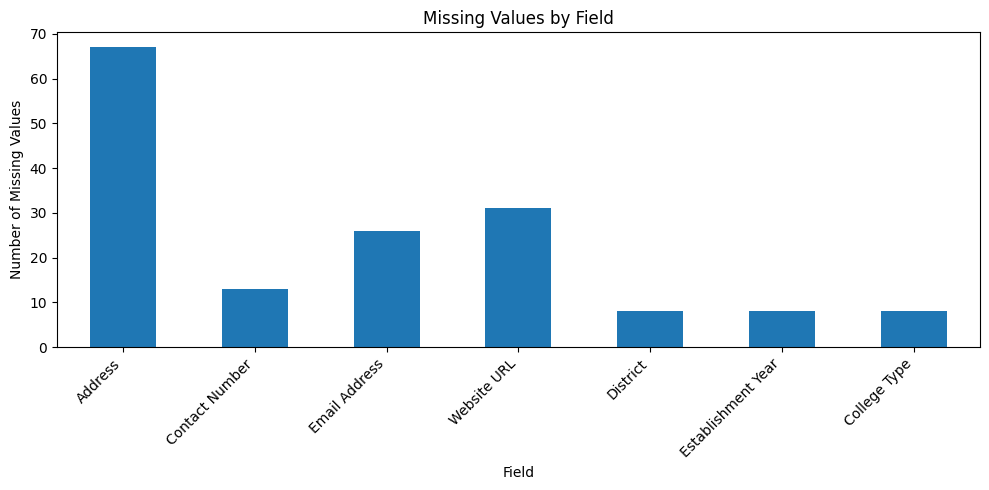

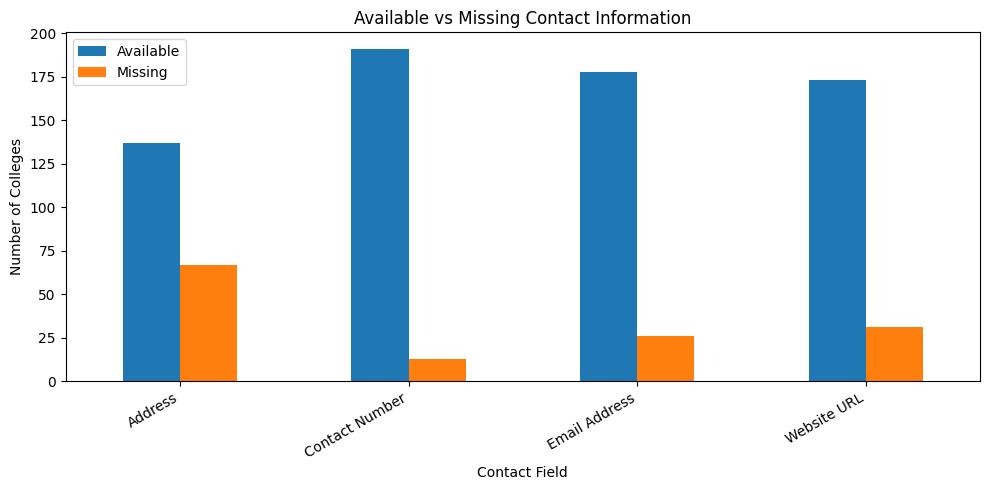

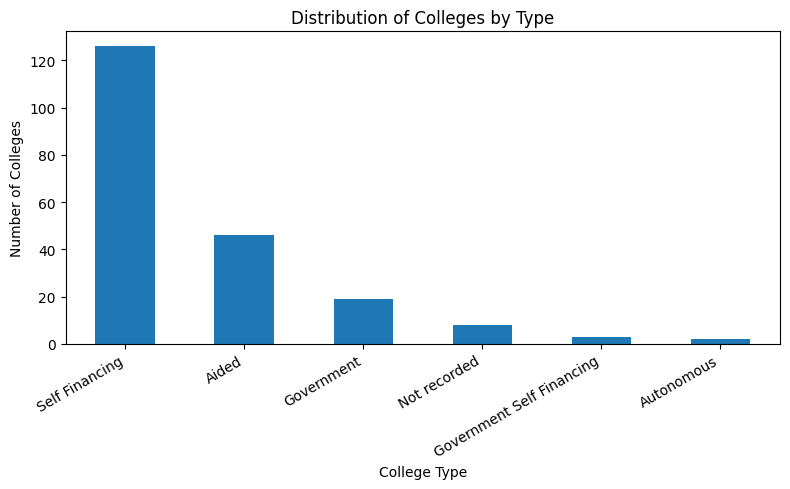

In [81]:

import matplotlib.pyplot as plt
import pandas as pd

# Make sure we have the enriched dataset
print("Total college records:", len(df_clean))

# -----------------------------------------
# Chart 1: Missing values by field
# -----------------------------------------
fields = [
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL",
    "District",
    "Establishment Year",
    "College Type"
]

missing_counts = df_clean[fields].isna().sum()

plt.figure(figsize=(10, 5))
missing_counts.plot(kind="bar")
plt.title("Missing Values by Field")
plt.xlabel("Field")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# -----------------------------------------
# Chart 2: Available vs missing contact fields
# -----------------------------------------
contact_fields = [
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL"
]

available = df_clean[contact_fields].notna().sum()
missing = df_clean[contact_fields].isna().sum()

comparison = pd.DataFrame({
    "Available": available,
    "Missing": missing
})

comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Available vs Missing Contact Information")
plt.xlabel("Contact Field")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# -----------------------------------------
# Chart 3: Colleges by type
# -----------------------------------------
type_counts = (
    df_clean["College Type"]
    .fillna("Not recorded")
    .value_counts()
)

plt.figure(figsize=(8, 5))
type_counts.plot(kind="bar")
plt.title("Distribution of Colleges by Type")
plt.xlabel("College Type")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [82]:

print("CONTACT INFORMATION SUMMARY")
for field in [
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL"
]:
    available_count = df_clean[field].notna().sum()
    missing_count = df_clean[field].isna().sum()

    print(
        f"{field}: "
        f"{available_count} available, "
        f"{missing_count} missing"
    )

print("\nCOLLEGE TYPE SUMMARY")
print(
    df_clean["College Type"]
    .fillna("Not recorded")
    .value_counts()
)

print("\nDISTRICT SUMMARY")
print(
    df_clean["District"]
    .fillna("Not recorded")
    .value_counts()
)


CONTACT INFORMATION SUMMARY
Address: 137 available, 67 missing
Contact Number: 191 available, 13 missing
Email Address: 178 available, 26 missing
Website URL: 173 available, 31 missing

COLLEGE TYPE SUMMARY
College Type
Self Financing               126
Aided                         46
Government                    19
Not recorded                   8
Government Self Financing      3
Autonomous                     2
Name: count, dtype: int64

DISTRICT SUMMARY
District
Thiruvananthapuram    88
Kollam                61
Alappuzha             34
Pathanamthitta        13
Not recorded           8
Name: count, dtype: int64


## 5. Exploratory Data Analysis and Visualizations

Exploratory Data Analysis (EDA) was performed on the enriched dataset containing 204 college records. Three visualizations were created using Matplotlib and Pandas to examine missing values, contact-information completeness, and college-type distribution.

### 5.1 Missing Values by Field

The missing-value analysis showed that address information had the highest number of missing values, with 67 records (32.8%). Website URLs were missing for 31 records (15.2%), email addresses for 26 records (12.7%), and contact numbers for 13 records (6.4%). District, establishment year, and college type each had 8 missing values.

**Interpretation:** Address information is the least complete field in the dataset. Additional verification of missing fields would improve the usefulness of the collected directory.

### 5.2 Available versus Missing Contact Information

The dataset contained contact numbers for 191 colleges, email addresses for 178 colleges, website URLs for 173 colleges, and addresses for 137 colleges.

**Interpretation:** Contact numbers had the highest completeness among the four contact fields, while addresses had the lowest. This comparison helps identify which fields require the most attention during data-quality improvement.

### 5.3 Distribution of Colleges by Type

The college-type distribution contained 126 Self Financing records, 46 Aided records, 19 Government records, 3 Government Self Financing records, and 2 Autonomous records. Eight records had no recorded college type.

**Interpretation:** Self Financing was the largest category in the collected dataset. These figures describe the extracted records and do not independently establish the distribution of all colleges affiliated with the university.

### 5.4 District-wise Summary

The extracted district values included 88 records from Thiruvananthapuram, 61 from Kollam, 34 from Alappuzha, and 13 from Pathanamthitta. District information was not recorded for 8 colleges.

**Interpretation:** Thiruvananthapuram represented the largest share of the collected records, followed by Kollam. The district summary should be interpreted in the context of the dataset's coverage and the accuracy of the extracted district values.

## 6. Key Findings and Recommendations

1. The final enriched dataset contains 204 college records and 10 columns.
2. Address information has the highest missing-value count, at 67 records.
3. Contact numbers are available for 191 records, making them the most complete of the four contact fields.
4. Email addresses are available for 178 records, and website URLs are available for 173 records.
5. Self Financing is the largest recorded college-type category, with 126 records.
6. Thiruvananthapuram has the largest number of records in the extracted district summary, with 88.
7. No duplicate college IDs, duplicate college names, or exact duplicate rows were detected in the current dataset.
8. All populated email addresses passed the selected basic format check, and all populated phone-number entries passed the preliminary length check. These checks do not establish that the contact details are active or current.

### Recommendations

- Verify missing contact information against the official college details pages.
- Review records with missing district, establishment year, or college type.
- Maintain a copy of the original dataset before applying cleaning operations.
- Record all data-cleaning changes and compare the dataset before and after cleaning.
- Validate contact details before using the dataset as an operational directory.
- Re-run the scraper periodically, with reasonable delays, to account for changes to the website.
- Confirm that the scraper captures all directory entries before describing the dataset as complete.


In [83]:

# Create a cleaned copy of your enriched dataset
df_final = df_updated.copy()

# Record the number of rows before cleaning
rows_before = len(df_final)

# Remove leading and trailing spaces from text fields
text_columns = df_final.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df_final[column] = df_final[column].apply(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

# Convert blank strings to missing values
df_final = df_final.replace(r"^\s*$", pd.NA, regex=True)

# Remove exact duplicate rows, if any
duplicates_before = df_final.duplicated().sum()
df_final = df_final.drop_duplicates()

print("Rows before cleaning:", rows_before)
print("Exact duplicate rows removed:", duplicates_before)
print("Rows after cleaning:", len(df_final))

# Show remaining missing values
print("\nMissing values after cleaning:")
print(df_final.isna().sum())

# Save the cleaned dataset
df_final.to_csv(
    "kerala_university_colleges_final.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFinal cleaned dataset saved!")


Rows before cleaning: 204
Exact duplicate rows removed: 0
Rows after cleaning: 204

Missing values after cleaning:
College Name           0
College ID             0
Address               67
Contact Number        13
Email Address         26
Website URL           31
Status                 0
District               8
Establishment Year     8
College Type           8
dtype: int64

Final cleaned dataset saved!
